# Mutations avec les règles V2

Les tests de mutation de V1 (`teste_newmut_V1/parametrage_regles.ipynb`, partie « Mutations »), refaits avec :
- les **règles V2**, lues dans `teste_newmut_V2/Rule_V2/parametrage_regles_V2.ipynb` (le sauvegarder après avoir
  changé une règle), plus la règle `RB` (ordre de liaison max sur un bore) si les marches l'avaient
  (`BORE_MAX_ORDRE`, ou `BORE_SIMPLE` pour les marches d'avant : B- seulement) ;
- les **molécules des marches V2** (`teste_newmut_V2/Walk_V2/resultats/`) et leurs
  **atomes** (C, O, N, B, F) ;
- les **réglages de mutation de ces marches** (lus dans leur `config.json`), sans leurs règles : les mutations sont
  listées sans règle, puis jugées par les règles V2.

Outils : ceux de V1 (`teste_newmut_V1/parametrage_regles.py`, `pr`), qui reçoivent ici le graphe V2
(`rv.GrapheV2` : `g.tags` donne l'état `s` / `d` / `t` de tous les atomes, B et F compris).

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir())
sys.path.insert(0, str(ROOT / "teste_newmut_V2" / "Rule_V2"))

from IPython.display import display

import marches_V2 as mv2            # teste_newmut_V2/Rule_V2/marches_V2.py : règles des marches V2
import regles_V2 as rv              # teste_newmut_V2/Rule_V2/regles_V2.py
pr = rv.pr                          # outils de V1 (teste_newmut_V1/parametrage_regles.py)

## Réglages et règles

`EXPERIENCE` : les marches d'où viennent les molécules et les réglages de mutation (`config.json` : atomes,
mutations de l'espace d'action et leurs options, `BORE_MAX_ORDRE`). Toutes les mutations de l'espace d'action sont
disponibles, pas seulement les 5 types tirés dans les marches (`ACTION_TYPES`) : `FAMILLES` choisit ensuite celles
qu'on teste. Les mutations qui appliquent elles-mêmes les règles (substitution, greffe…) les prennent aussi dans
les règles V2 (`mv2.install`), comme dans les marches.

Les mutations qui donneraient un bore d'ordre de liaison interdit (`B#` avec `BORE_MAX_ORDRE = 2`) ne sont pas
proposées du tout (`mv2.hide_forbidden_bore`) : ni dans les tests, ni dans les essais à la main.


In [2]:
DOSSIER_MARCHES = ROOT / "teste_newmut_V2" / "Walk_V2" / "resultats"   # marches de newmut_walk_V2.ipynb
EXPERIENCE = "test_Regle_V2_Bd"   # relatif à DOSSIER_MARCHES
CONFIG_MARCHES = json.loads((DOSSIER_MARCHES / EXPERIENCE / "config.json").read_text())
BORE_MAX = mv2.bore_max_order(CONFIG_MARCHES)    # ordre de liaison max sur un B (None : pas de RB)

mv2.nw.configure({**CONFIG_MARCHES, "MATRIX_RULES": False})   # espace d'action des marches, sans les règles d'evomol
REGLES = mv2.install(bore_max=BORE_MAX)                        # règles V2 (+ RB) : notebook et mutations d'evomol
mv2.hide_forbidden_bore(BORE_MAX)   # mutations qui donneraient un B# : pas proposées (ni candidates, ni refusées)

print("atomes :", ", ".join(CONFIG_MARCHES["ACCEPTED_ATOMS"]), "· ordre max sur B :", BORE_MAX)
print("familles :", ", ".join(pr.families()))
display(REGLES.legend())

atomes : C, O, N, B, F · BORE_SIMPLE : True
familles : AddAtomMG, ChangeBondMG, CutAtomMG, InsertCarbonMG, MoveGroupMG, RemoveAtomMG, SubstituteShiftMG, GraftFragmentMG, AnnelateMG, FlipAlternatingPathMG, AromatizeMG


## Sous-familles de mutations

Comme en V1 (même découpage, voir le tableau de `parametrage_regles.ipynb`), avec l'étiquette V2 : élément + état
`s`, `d` ou `t` pour **tous** les atomes (V1 : C, N, O seulement), donc `Bs`, `Fs`, `Bd`… Exemples : `addBs@Cd`
(B ajouté par une simple sur un C `d`), `addBd@Cs`, `bondBC1→2`, `subCd→Bs+abaiss`, `rmFs@Cd`.

`AJOUT_COMPLET = True` : l'ajout d'atome propose chaque élément accepté avec une liaison simple, double ou triple dès
que la valence le permet, et la substitution tous ses états : **ce sont les règles qui trient**. `False` : les
candidates des mutations elles-mêmes.

Une mutation est **permise** si elle ne crée aucune nouvelle violation (R1 comptée à part, les autres ensemble, comme
dans les marches) ; **règles cassées** : celles dont le nombre de violations augmente.

In [3]:
AJOUT_COMPLET = True   # toutes les candidates, sans tri interne ; False : celles des mutations

ORDRE = {1: "s", 2: "d", 3: "t"}
LIAISON = {1: "-", 2: "=", 3: "#"}


def atome(g, i):
    """Élément et état s / d / t (tous les éléments) : « Cs », « Nd », « Bs », « Fs »."""
    return g.types[i] + g.tags[i]


def SOUS_FAMILLE(action, avant, apres):
    """Nom de la sous-famille d'une mutation. avant, apres : rv.GrapheV2 (numéros de départ ; atomes ajoutés à la fin)."""
    famille = pr.family_label(action.class_name())   # une seule étiquette par famille
    if famille == "AddAtomMG":
        ajout = f"add{action.atom_type}{ORDRE[action.bond_order]}"
        if avant.n == 0:
            return ajout                                    # molécule vide : pas d'atome d'ancrage
        return f"{ajout}@{atome(avant, action.index_atom)}"  # « addBs@Cd » : B s ajouté sur un C d
    if famille == "ChangeBondMG":
        x, y = sorted((avant.types[action.atom1], avant.types[action.atom2]))
        return f"bond{x}{y}{avant.order[action.atom1][action.atom2]}→{action.bond_type}"
    if famille == "SubstituteShiftMG":
        i = action.atom_idx
        changes = getattr(action, "bond_changes", ())
        if not changes:
            suffixe = ""
        elif not all(i in (a, b) for a, b, _ in changes):
            suffixe = "+dépl"       # des doubles sont déplacées le long d'un chemin alterné (comme un FlipPath)
        elif any(ordre > avant.order[a][b] for a, b, ordre in changes):
            suffixe = "+mont"       # une liaison de l'atome substitué monte
        else:
            suffixe = "+abaiss"     # seules les liaisons de l'atome substitué sont abaissées (comme un ChangeBond)
        return f"sub{atome(avant, i)}→{atome(apres, i)}{suffixe}"
    if famille == "RemoveAtomMG":
        # RemoveAtomMG ne retire que des atomes en bout de chaîne : « rmFs@Cd » = F retiré d'un C d
        i = action.atom_idx
        if not avant.adj[i]:
            return f"rm{atome(avant, i)}"                       # molécule d'un seul atome
        return f"rm{atome(avant, i)}@{atome(avant, avant.adj[i][0])}"
    if famille == "CutAtomMG":
        # atome retiré (exactement 2 voisins, reliés ensuite entre eux) et ses deux voisins : « cutBs@Cd,Cd »
        voisins = sorted((atome(avant, action.atom1_to_bond), atome(avant, action.atom2_to_bond)))
        return f"cut{atome(avant, action.atom_to_cut)}@{voisins[0]},{voisins[1]}"
    if famille == "InsertCarbonMG":
        # fragment obtenu A–C–B (atomes de la liaison coupée avec leur état avant, liaisons au C inséré) et
        # liaison coupée entre parenthèses : « insCd=C-Cd(=) »
        a, b = action.atom1_idx_to_bond, action.atom2_idx_to_bond
        cote_a = (atome(avant, a), LIAISON[action.bond_to_1])
        cote_b = (atome(avant, b), LIAISON[action.bond_to_2])
        (x, lx), (y, ly) = sorted((cote_a, cote_b))
        return f"ins{x}{lx}C{ly}{y}({LIAISON[avant.order[a][b]]})"
    if famille == "MoveGroupMG":
        return "move"
    if famille == "GraftFragmentMG":
        return f"graft_{action.name}"
    if famille == "AnnelateMG":
        return f"annel_{action.name}"
    if famille == "FlipAlternatingPathMG":
        return "flip"
    if famille == "AromatizeMG":
        return "aromatize"
    if famille == "AddGroupMG":
        return f"group+_{action.smiles}"
    if famille == "RemoveGroupMG":
        return "group-"
    return famille

### Une molécule : permises et refusées par sous-famille

Le tableau par sous-famille (candidates, permises, refusées, règles cassées par les refusées), puis pour `NOM` (une
sous-famille, une famille, ou un motif comme `"add*"`, `"bondBC*"`, `"sub*"`) : le tableau des permises, celui des
refusées, et les dessins (refusées groupées par règles cassées).

candidates  permises  refusées  \
famille               sous-famille                                          
AddAtomMG             addBd@Bs                      1         0         1   
                      addBs@Bs                      1         0         1   
                      addBs@Cd                      4         4         0   
                      addCd@Bs                      1         0         1   
                      addCs@Bs                      1         0         1   
                      addCs@Cd                      4         4         0   
                      addFs@Bs                      1         0         1   
                      addFs@Cd                      4         4         0   
                      addNd@Bs                      1         0         1   
                      addNs@Bs                      1         0         1   
                      addNs@Cd                      4         4         0   
                      addOd@Bs                      1         0         1   
                      addOs@Bs                      1         0         1   
                      addOs@Cd                      4         4         0   
ChangeBondMG          bondBC0→1                     4         2         2   
                      bondCC0→1                     4         4         0   
                      bondCC1→0                     3         3         0   
                      bondCC1→2                     1         0         1   
                      bondCC2→1                     3         1         2   
                      bondCC2→3                     1         1         0   
CutAtomMG             cutCd@Cd,Cd                   4         2         2   
InsertCarbonMG        insBs-C-Cd(-)                 1         0         1   
                      insCd-C-Cd(-)                 3         3         0   
                      insCd-C-Fs(-)                 1         0         1   
                      insCd-C=Cd(=)                 6         4         2   
MoveGroupMG           move                          9         8         1   
RemoveAtomMG          rmBs@Cd                       1         1         0   
                      rmFs@Cd                       1         1         0   
SubstituteShiftMG     subBs→Cs                      1         1         0   
                      subBs→Fs                      1         1         0   
                      subBs→Ns                      1         1         0   
                      subBs→Os                      1         1         0   
                      subCd→Bd                      4         0         4   
                      subCd→Nd                      4         4         0   
                      subFs→Bs                      1         1         0   
                      subFs→Cs                      1         1         0   
                      subFs→Ns                      1         1         0   
                      subFs→Os                      1         1         0   
GraftFragmentMG       graft_cyano                   5         5         0   
                      graft_dicyanovinyl            5         5         0   
                      graft_dimethylamino           5         0         5   
                      graft_ethynyl                 5         5         0   
                      graft_methoxy                 5         0         5   
                      graft_phenyl                  5         5         0   
                      graft_vinyl                   5         5         0   
AnnelateMG            annel_benzo                   2         2         0   
FlipAlternatingPathMG flip                          5         0         5   

                                           % acceptées  % refusées  \
famille               sous-famille                                   
AddAtomMG             addBd@Bs                     0.0       100.0   
                      addBs@Bs                     0.0     

,n°,sous-famille,mutation,résultat,permise,règles cassées
9,9,addCs@Cd,+C sur C2,Bc1ccc(F)cc1C,True,
10,10,addOs@Cd,+O sur C2,Bc1ccc(F)cc1O,True,
11,11,addNs@Cd,+N sur C2,Bc1ccc(F)cc1N,True,
12,12,addBs@Cd,+B sur C2,Bc1ccc(F)cc1B,True,
13,13,addFs@Cd,+F sur C2,Bc1ccc(F)cc1F,True,
14,14,addCs@Cd,+C sur C3,Bc1ccc(F)c(C)c1,True,
15,15,addOs@Cd,+O sur C3,Bc1ccc(F)c(O)c1,True,
16,16,addNs@Cd,+N sur C3,Bc1ccc(F)c(N)c1,True,
17,17,addBs@Cd,+B sur C3,Bc1ccc(F)c(B)c1,True,
18,18,addFs@Cd,+F sur C3,Bc1ccc(F)c(F)c1,True,


,n°,sous-famille,mutation,résultat,permise,règles cassées
0,0,addCs@Bs,+C sur B0,CBc1ccc(F)cc1,False,R2
1,1,addCd@Bs,+=C sur B0,C=Bc1ccc(F)cc1,False,RB
2,2,addOs@Bs,+O sur B0,OBc1ccc(F)cc1,False,R2
3,3,addOd@Bs,+=O sur B0,O=Bc1ccc(F)cc1,False,RB
4,4,addNs@Bs,+N sur B0,NBc1ccc(F)cc1,False,R2
5,5,addNd@Bs,+=N sur B0,N=Bc1ccc(F)cc1,False,RB
6,6,addBs@Bs,+B sur B0,BBc1ccc(F)cc1,False,R2
7,7,addBd@Bs,+=B sur B0,B=Bc1ccc(F)cc1,False,RB
8,8,addFs@Bs,+F sur B0,FBc1ccc(F)cc1,False,R2



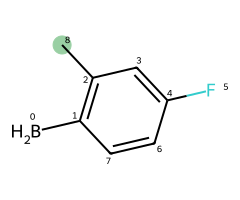
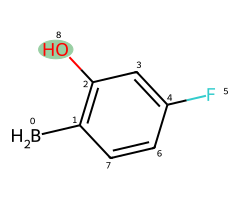
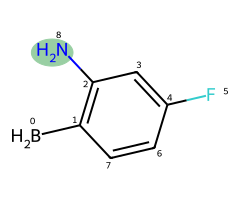
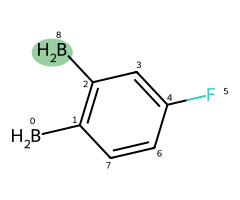
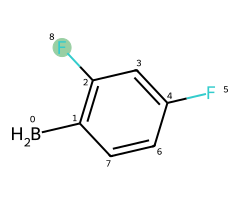
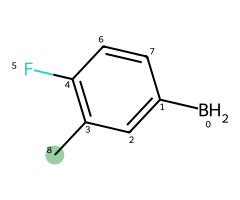
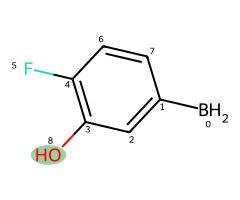
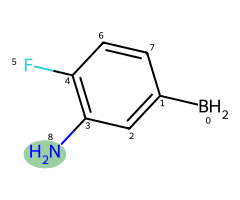
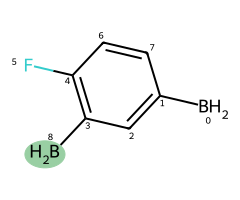
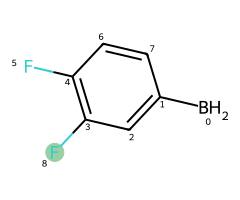
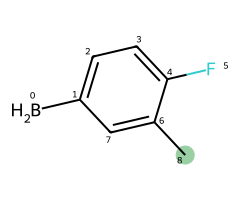
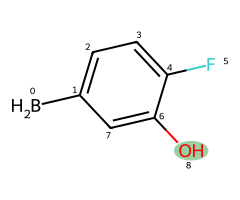
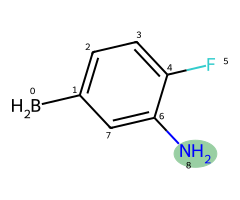
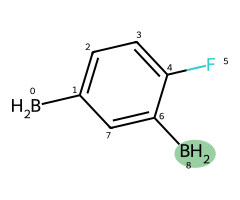
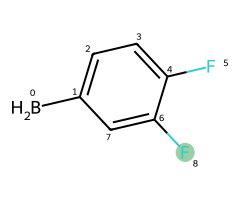
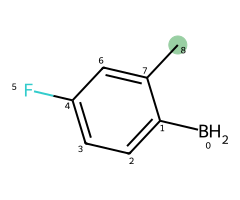
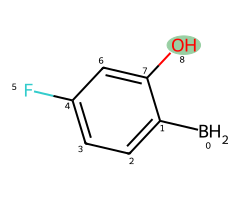
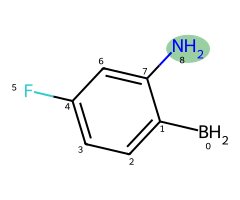
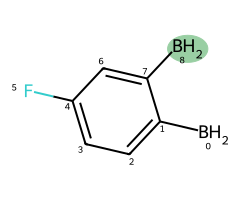
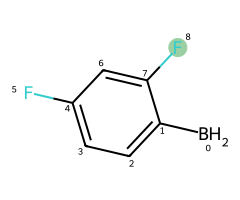


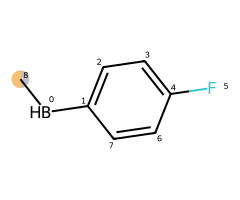
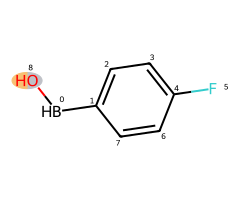
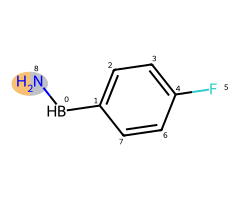
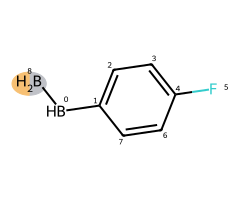
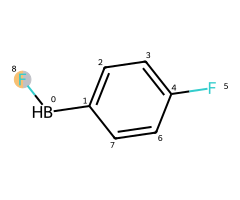


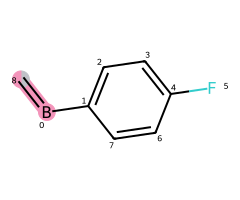
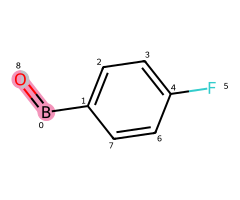
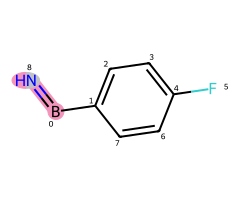
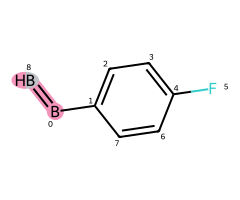

In [4]:
MOLECULE = "BC1=CC=C(F)C=C1"
NOM = "add*"

display(pr.subfamily_summary(MOLECULE, REGLES, SOUS_FAMILLE, AJOUT_COMPLET))
table_sf = pr.subfamily_table(MOLECULE, NOM, REGLES, SOUS_FAMILLE, AJOUT_COMPLET)
pr.show_subfamily(MOLECULE, NOM, REGLES, SOUS_FAMILLE, AJOUT_COMPLET)

## Test d'une mutation sur les molécules des marches V2

### Molécules du test

`N_TEST` molécules différentes tirées dans les marches de `EXPERIENCE` (20 marches de 1500 pas), en ne gardant que
celles qui respectent toutes les règles (V2 + `RB`) : les statistiques ne comptent ainsi que ce que la mutation
casse. Même graine : mêmes molécules, tant que les règles ne changent pas.

In [ ]:
SEED_TEST = 0
N_TEST = 30000
MAX_ATOMS_TEST = None     # None : toutes les tailles

MOLECULES_TEST = pr.sample_valid(N_TEST, REGLES, seed=SEED_TEST, max_atoms=MAX_ATOMS_TEST, names=[EXPERIENCE],
                                 results_dir=str(DOSSIER_MARCHES))
display(MOLECULES_TEST.atomes.describe().to_frame("atomes lourds").T)

12570 tirées : 2496 doublons, 0 illisibles, 74 hors règles, 10000 gardées


,count,mean,std,min,25%,50%,75%,max
atomes lourds,10000.0,26.8385,15.760598,2.0,15.0,23.0,36.0,86.0


### Statistiques

`FAMILLES` : les familles testées (seules leurs mutations sont listées ; noms : `pr.families()` ; `None` : toutes,
lent), puis seules celles de `SELECTION` (sous-familles ou motifs : `["addBd"]`, `["add*"]`, `["bondBC*"]` ;
`None` : toutes celles des familles choisies) sont jugées par les règles. `N_JOBS` : nombre de cœurs (-1 : tous ;
même résultat qu'avec un seul). Puis :
1. un tableau par sous-famille : candidates, acceptées, refusées (nombres et %), règles qui refusent, une colonne
   par règle avec le nombre de refus qui la cassent, et les refus où une seule règle est cassée ;
2. les combinaisons de règles cassées les plus fréquentes, par sous-famille.

Les mutations qui donneraient un `B#` ne sont pas proposées (voir « Réglages et règles ») ;
`mv2.drop_forbidden_bore` le vérifie (0 retirée attendu).

Le tableau est écrit dans `teste_newmut_V2/Mutation_V2/parametre/{FAMILLES}.csv`.

In [6]:
FAMILLES = ["AddAtomMG"]   # familles testées ; None : toutes (lent)
SELECTION = None           # ex. ["addBd"] pour une seule sous-famille
N_JOBS = -1                # cœurs (-1 : tous)

essai = pr.mutation_test(MOLECULES_TEST, REGLES, SOUS_FAMILLE, SELECTION, AJOUT_COMPLET, familles=FAMILLES,
                         progress_every=1000, n_jobs=N_JOBS)
essai = mv2.drop_forbidden_bore(essai)   # pas de B# : ces mutations ne sont pas possibles
display(REGLES.legend())
display(pr.test_table(essai, REGLES))
display(pr.test_combinations(essai))

DOSSIER_RESULTATS = ROOT / "teste_newmut_V2" / "Mutation_V2" / "parametre"
pr.save_test_table(essai, REGLES, str(DOSSIER_RESULTATS / f"{pr.families_name(FAMILLES)}.csv"))

  1099/10000 molécules, 59637 mutations, 6 s
  2041/10000 molécules, 111588 mutations, 10 s
  3140/10000 molécules, 172246 mutations, 14 s
  4082/10000 molécules, 224663 mutations, 19 s
  5024/10000 molécules, 277153 mutations, 20 s
  6123/10000 molécules, 338636 mutations, 25 s
  7065/10000 molécules, 392043 mutations, 30 s
  8007/10000 molécules, 444784 mutations, 34 s
  9106/10000 molécules, 504173 mutations, 40 s
  10000/10000 molécules, 555791 mutations, 44 s
555791 mutations sur 10000 molécules en 43.8 s


,sous-famille,règles cassées,mutations,% des refusées
0,addCs@Bs,R2,13663,100.0
1,addOs@Bs,R2,13663,100.0
2,addNs@Bs,R2,13663,100.0
3,addBs@Bs,R2,13663,100.0
4,addFs@Bs,R2,13663,100.0
5,addCs@Cs,"R2, R3b",5042,53.4
6,addCs@Cs,R2,4397,46.6
7,addOs@Cs,"R2, R3b",5042,53.4
8,addOs@Cs,R2,4397,46.6
9,addNs@Cs,"R2, R3b",5042,53.4


tableau : /Users/LeaClautour/Desktop/RevoMol/teste_newmut_V2/Mutation_V2/parametre/AddAtomMG.csv


'/Users/LeaClautour/Desktop/RevoMol/teste_newmut_V2/Mutation_V2/parametre/AddAtomMG.csv'

### Exemples tirés dans le test : acceptées à gauche, refusées à droite

À gauche `N_EX` acceptées, à droite `N_EX` refusées : la molécule de départ (atomes modifiés), puis le résultat
(atomes des nouvelles violations de la couleur de leur règle). `REGLE_EX` : seulement les refus qui cassent cette
règle. Une image par sous-famille, dans `teste_newmut_V2/Mutation_V2/parametre/{FAMILLES}/{sous-famille}.png`
(`→` devient `-` dans le nom) ; celle de `NOM_EX` est affichée par la cellule suivante.

In [7]:
REGLE_EX = None     # refusées : seulement celles qui cassent cette règle (None : toutes)
N_EX = 8            # exemples de chaque côté

DOSSIER_IMAGES = DOSSIER_RESULTATS / pr.families_name(FAMILLES)
images = pr.test_examples_images(essai, REGLES, str(DOSSIER_IMAGES), REGLE_EX, n=N_EX, seed=0)

  1/54 addCs@Bs
  2/54 addOs@Bs
  3/54 addNs@Bs
  4/54 addBs@Bs
  5/54 addFs@Bs
  6/54 addCs@Cs
  7/54 addCd@Cs
  8/54 addOs@Cs
  9/54 addOd@Cs
  10/54 addNs@Cs
  11/54 addNd@Cs
  12/54 addBs@Cs
  13/54 addBd@Cs
  14/54 addFs@Cs
  15/54 addCs@Cd
  16/54 addOs@Cd
  17/54 addNs@Cd
  18/54 addBs@Cd
  19/54 addFs@Cd
  20/54 addCs@Ns
  21/54 addOs@Ns
  22/54 addNs@Ns
  23/54 addBs@Ns
  24/54 addFs@Ns
  25/54 addCt@Cs
  26/54 addNt@Cs
  27/54 addBt@Cs
  28/54 addCd@Ns
  29/54 addOd@Ns
  30/54 addNd@Ns
  31/54 addBd@Ns
  32/54 addCs@Nd
  33/54 addOs@Nd
  34/54 addNs@Nd
  35/54 addBs@Nd
  36/54 addFs@Nd
  37/54 addCd@Bs
  38/54 addOd@Bs
  39/54 addNd@Bs
  40/54 addBd@Bs
  41/54 addCd@Cd
  42/54 addOd@Cd
  43/54 addNd@Cd
  44/54 addBd@Cd
  45/54 addCs@Os
  46/54 addOs@Os
  47/54 addNs@Os
  48/54 addBs@Os
  49/54 addFs@Os
  50/54 addCs@Ct
  51/54 addOs@Ct
  52/54 addNs@Ct
  53/54 addBs@Ct
  54/54 addFs@Ct
54 images dans /Users/LeaClautour/Desktop/RevoMol/teste_newmut_V2/Mutation_V2/parametre/Add

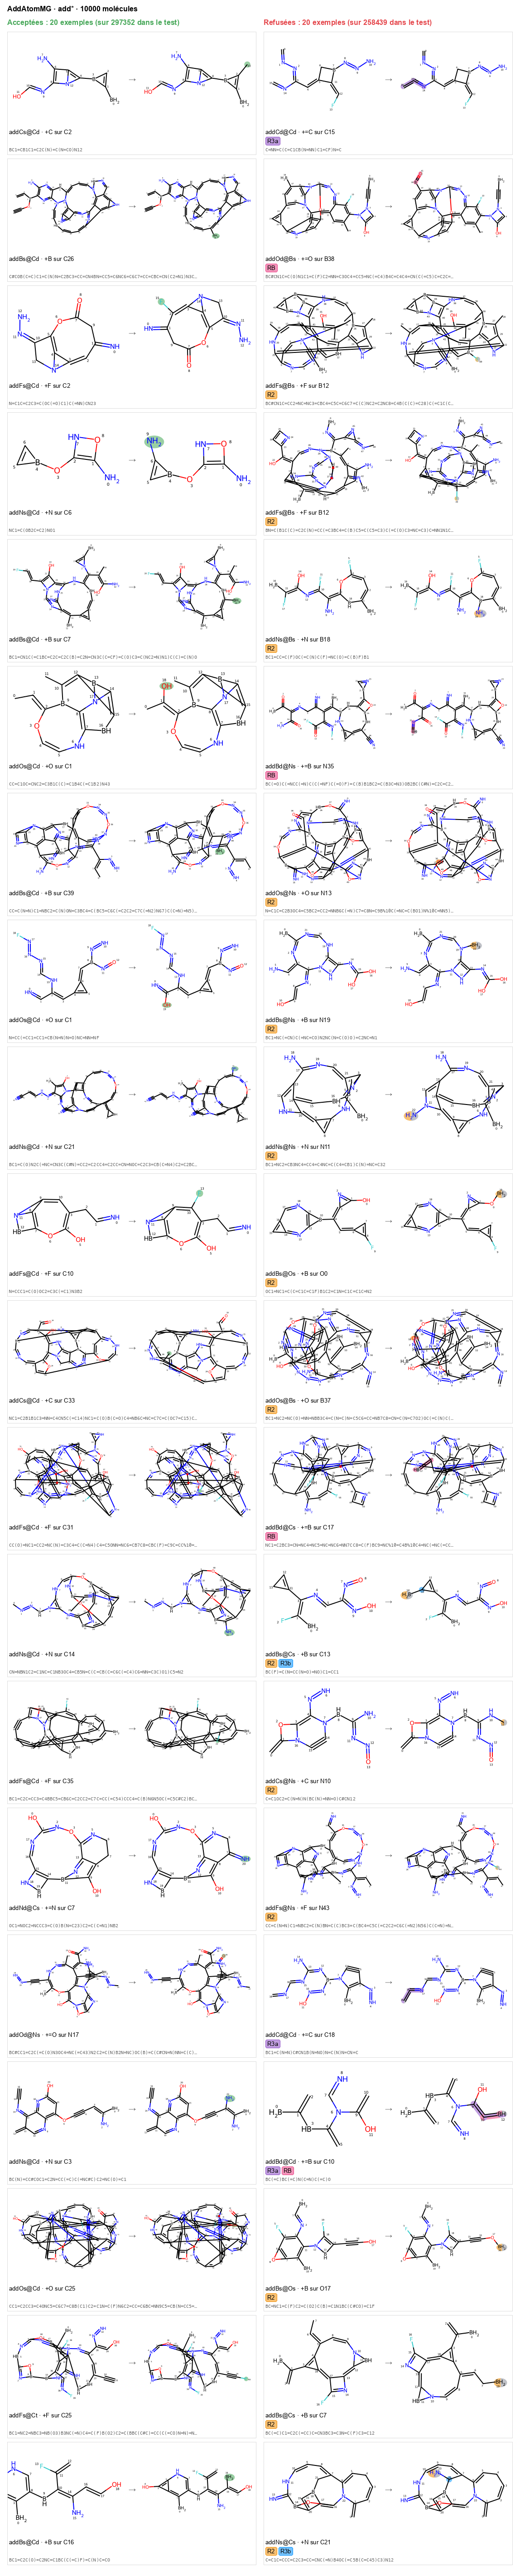

In [8]:
REGLE_EX = None     # refusées : seulement celles qui cassent cette règle (None : toutes)
N_EX = 20           # exemples de chaque côté
NOM_EX = "add*"    # sous-famille ou motif

image = pr.test_examples_image(essai, REGLES, NOM_EX, REGLE_EX, n=N_EX, seed=0)
display(image)

## Règles de mutation : autorisées, interdites, et par quelle règle

À écrire **à la main** dans `REGLES_MUTATION`, une ligne par sous-famille (ou motif) :
`(motif, verdict, règle(s) qui interdisent, commentaire)`, comme en V1 ; verdict `"autorisée"`, `"interdite"` ou
`"dépend"` ; règles : celles de `REGLES` (`"R1"`, `"R2"`, `"R3a"`, `"R3b"`, `"R4"`, `"RB"`). Une sous-famille prend
la **première** ligne qui lui correspond : écrire les cas précis avant les cas généraux. Vide pour l'instant (les
règles de V1 ne s'appliquent plus : R2a, R2b, R2c, R3, R5 n'existent pas en V2).

In [9]:
REGLES_MUTATION = [
    # ("addBt*", "interdite", "RB", "triple liaison sur un B"),   # exemple de ligne
]

### Comparaison avec le test

Pour chaque sous-famille du test (`essai`) : la ligne qui s'applique, le verdict écrit, ce qui est observé, et
l'écart (`OK`, ou `non écrite` si aucune ligne ne correspond).

In [10]:
display(pr.check_mutation_rules(essai, REGLES_MUTATION, REGLES))

0 sous-familles conformes, 54 non écrites, 0 en écart, sur 54 présentes dans le test


## Mutations d'une molécule, à la main

### Mutations possibles, par type

`candidates` : mutations que le type sait faire ; `permises (notebook)` / `permises (evomol)` : celles que chaque
jeu de règles laisse passer (ici les deux sont les règles V2 : evomol les reçoit par `mv2.install`) ;
`différences` : mutations où les deux ne sont pas d'accord (attendu : aucune).


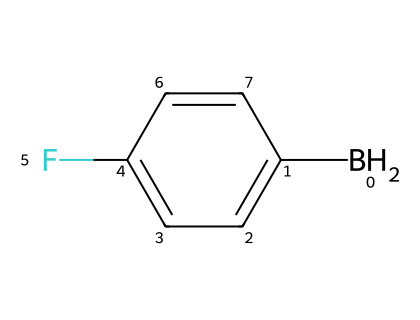

,candidates,permises (notebook),permises (evomol),différences,molécules différentes
mutation,,,,,
AddAtomMG,29,20,20,0,10
ChangeBondMG,16,11,11,0,9
CutAtomMG,4,2,2,0,1
InsertCarbonMG,11,7,7,0,3
MoveGroupMG,9,8,8,0,2
RemoveAtomMG,2,2,2,0,2
SubstituteShiftMG,12,12,12,0,10
GraftFragmentMG,35,25,25,0,15
AnnelateMG,2,2,2,0,1


In [11]:
SMILES = "BC1=CC=C(F)C=C1"

pr.show_rules(SMILES, REGLES)
display(pr.mutation_summary(SMILES, REGLES))

### Toutes les mutations d'un type

Numéros d'atomes : ceux de la molécule de départ (les atomes ajoutés prennent les numéros suivants). Atomes
modifiés en **vert** si la mutation est permise, en **gris** si elle est refusée ; atomes des nouvelles violations
de la couleur de leur règle.

,n°,mutation,résultat,permise,permise evomol,raison
0,0,+C sur B0,CBc1ccc(F)cc1,False,False,R2 +1
1,1,+=C sur B0,C=Bc1ccc(F)cc1,False,False,RB +1
2,2,+O sur B0,OBc1ccc(F)cc1,False,False,R2 +1
3,3,+=O sur B0,O=Bc1ccc(F)cc1,False,False,RB +1
4,4,+N sur B0,NBc1ccc(F)cc1,False,False,R2 +1
5,5,+=N sur B0,N=Bc1ccc(F)cc1,False,False,RB +1
6,6,+B sur B0,BBc1ccc(F)cc1,False,False,R2 +1
7,7,+=B sur B0,B=Bc1ccc(F)cc1,False,False,RB +2
8,8,+F sur B0,FBc1ccc(F)cc1,False,False,R2 +1
9,9,+C sur C2,Bc1ccc(F)cc1C,True,True,



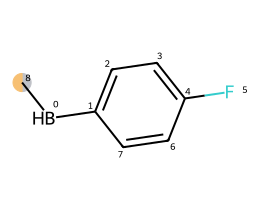
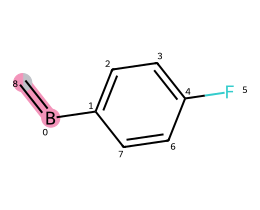
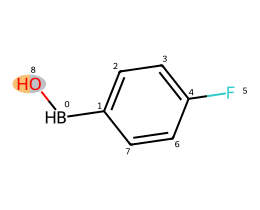
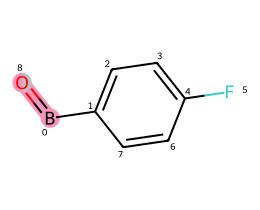
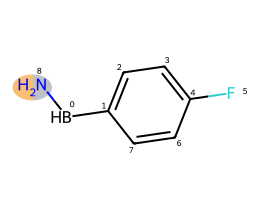
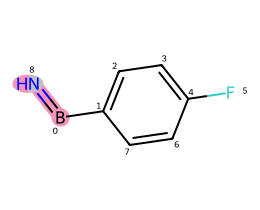
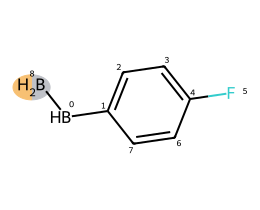
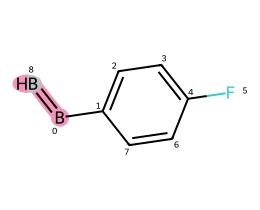
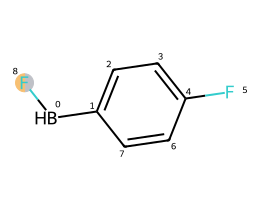
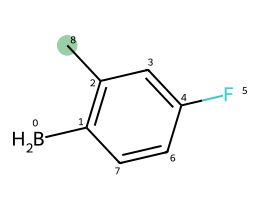
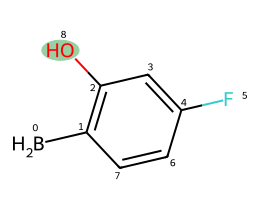
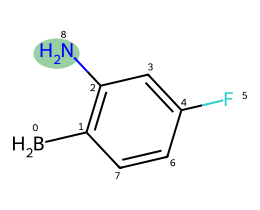
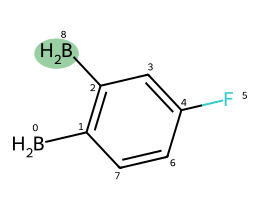
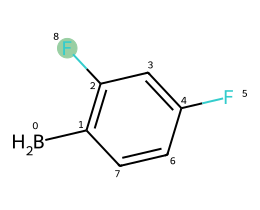
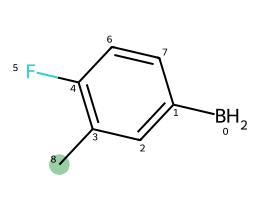
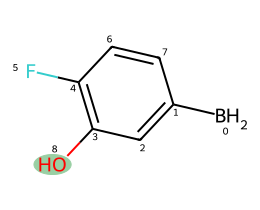
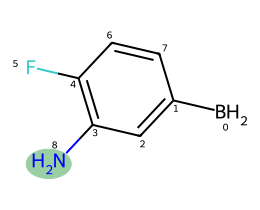
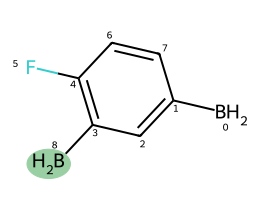
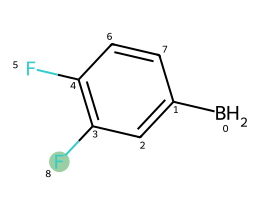
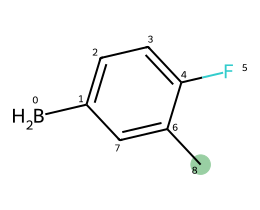
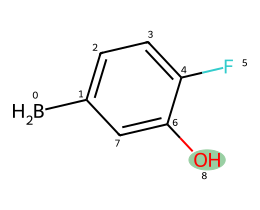
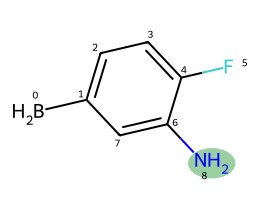
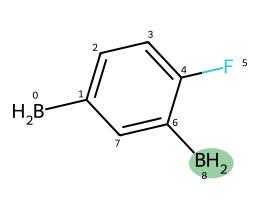
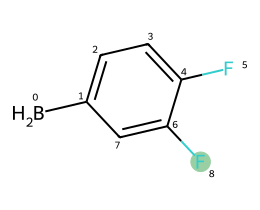
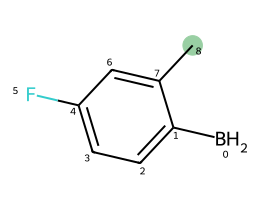
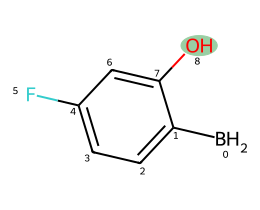
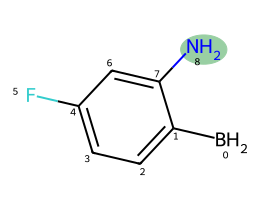
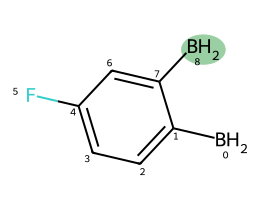
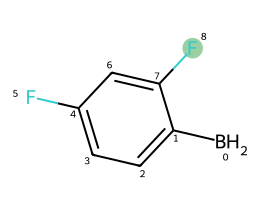

In [12]:
TYPE = "AddAtomMG"     # un nom de la liste ci-dessus

display(pr.mutation_table(SMILES, TYPE, REGLES))
display(pr.show_mutations(SMILES, TYPE, REGLES, only_allowed=False))

### Appliquer une mutation

Le n° est celui du tableau. Une mutation refusée est appliquée quand même, avec un avertissement, pour la voir. La
cellule met la nouvelle molécule dans `SMILES` : relancer les cellules précédentes avant de choisir le n° suivant
(atomes renumérotés).

Attention : mutation refusée par les règles du notebook (R2 +1), appliquée quand même pour la voir.
+C sur B0
  opération : Ajout de C8 sur B0
  case (B0, C8) : 0 → 1
  règles du notebook : R2 +1 ; evomol : refusée



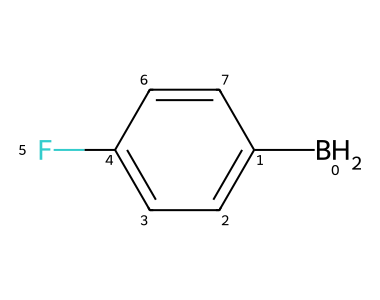
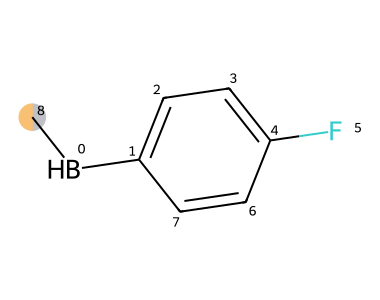

'CBC1=CC=C(F)C=C1'

In [13]:
NUMBER = 0

SMILES = pr.apply_mutation(SMILES, TYPE, NUMBER, REGLES)
SMILES

### Tirage au hasard, comme l'algorithme

À chaque fois un type de mutation au hasard, puis une mutation permise par les règles au hasard.


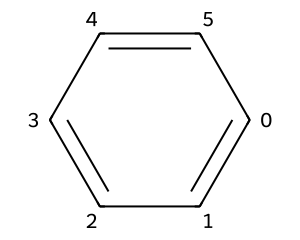
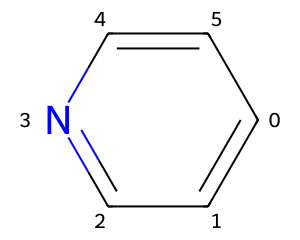
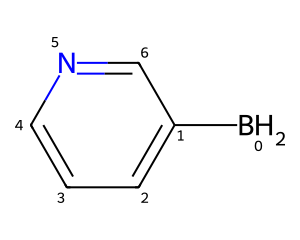
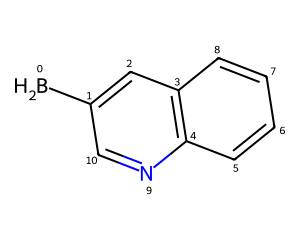
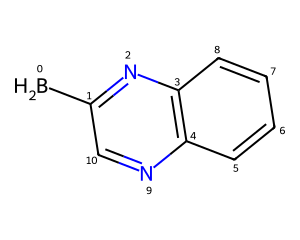
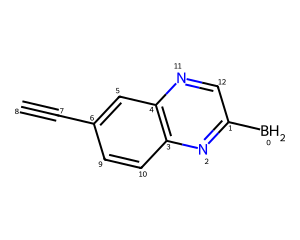
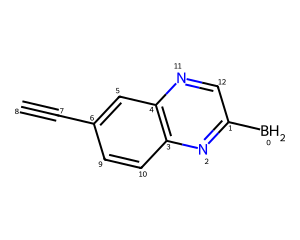
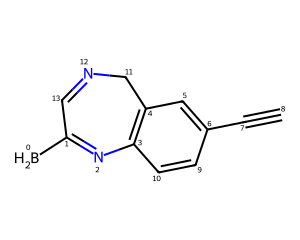
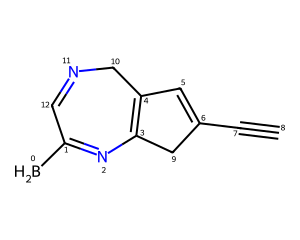

'BC1=NC2=C(C=C(C#C)C2)CN=C1'

In [14]:
pr.random_mutations("c1ccccc1", 8, REGLES, seed=0)